**Nama: Yuma Hazza Yuditama** <br>
**NIM: 24060124120035** <br>
**Lab: C1** <br>
**Materi: Klasifikasi** <br>

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer

from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier
)
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)

RANDOM_STATE = 42

# 1. Exploratory Data Analysis

In [4]:
DATA_PATH = "/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv"

df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())

print("\n")
print("="*100)
print("Cek kondisi dataset:")
display(df.info())

print("\n")
print("="*100)
missing = df.isna().sum().sort_values(ascending=False)
print("Jumlah missing value per kolom:")
display(missing[missing > 0] if (missing > 0).any() else missing.to_frame("missing_value"))

Ukuran dataset: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0




Cek kondisi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


None



Jumlah missing value per kolom:


,missing_value
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


Distribusi target:


,Jumlah
Exited,
Tidak churn,7963
Churn,2037


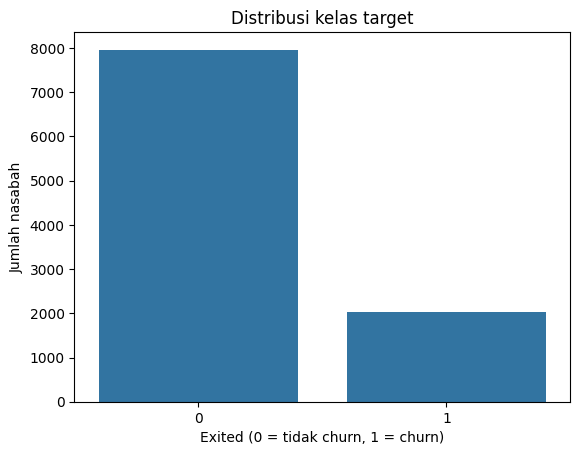

Proporsi kelas:


Exited
0    0.7963
1    0.2037
Name: Proporsi, dtype: float64

In [5]:
TARGET = "Exited"

print("Distribusi target:")
display(df[TARGET].value_counts().rename(index={0: "Tidak churn", 1: "Churn"}).to_frame("Jumlah"))

ax = sns.countplot(data=df, x=TARGET)
ax.set_title("Distribusi kelas target")
ax.set_xlabel("Exited (0 = tidak churn, 1 = churn)")
ax.set_ylabel("Jumlah nasabah")
plt.show()

print("Proporsi kelas:")
display(df[TARGET].value_counts(normalize=True).rename("Proporsi"))

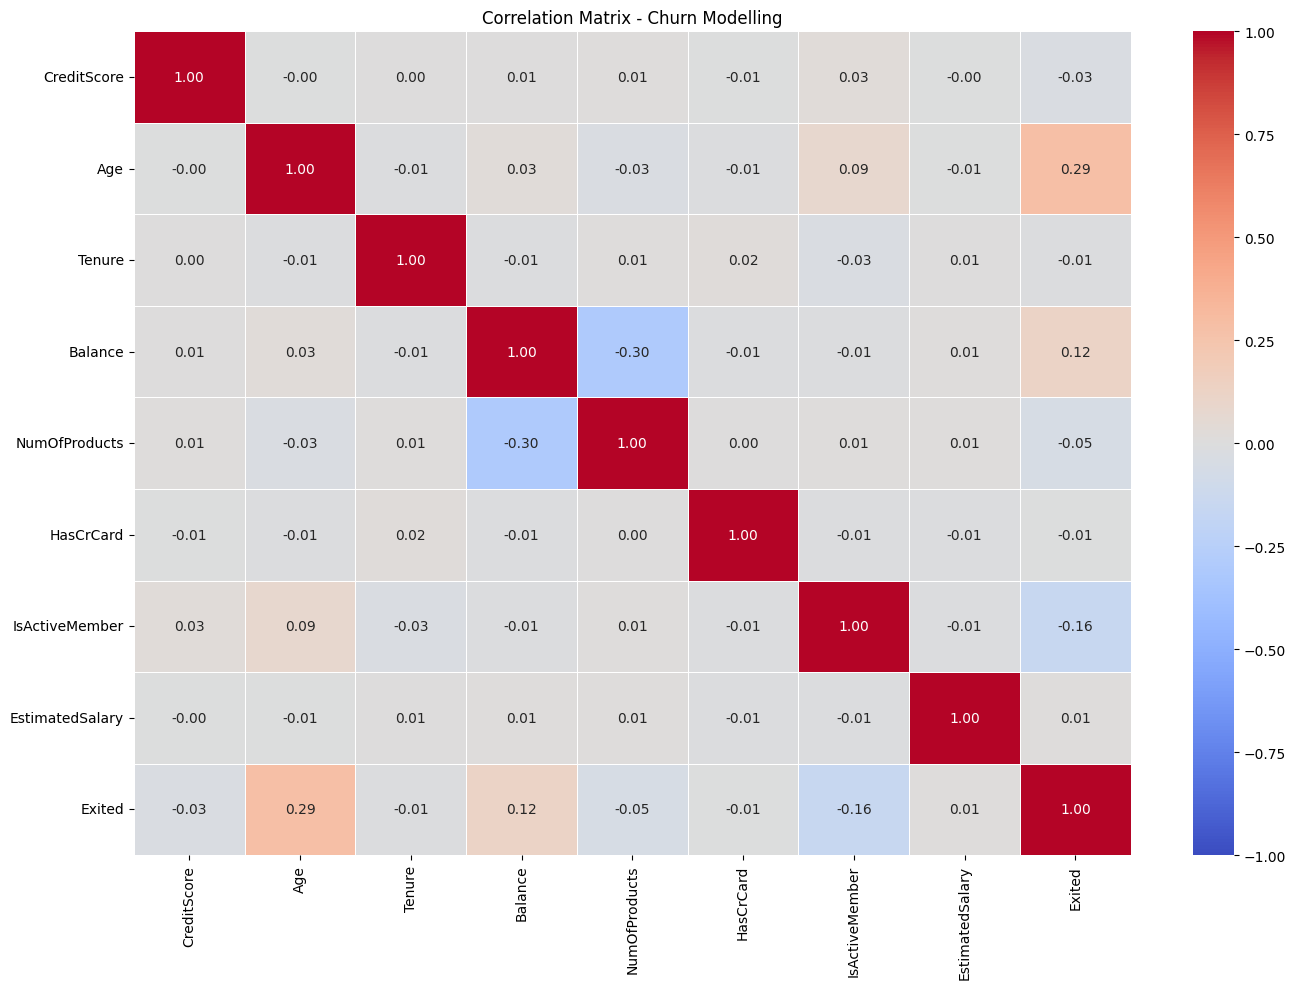

In [6]:
numerical_features = df.drop(columns=['RowNumber', 'CustomerId']).select_dtypes(include=["int64", "float64"])
correlation_matrix = numerical_features.corr(method="pearson")

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix - Churn Modelling")
plt.tight_layout()
plt.show()

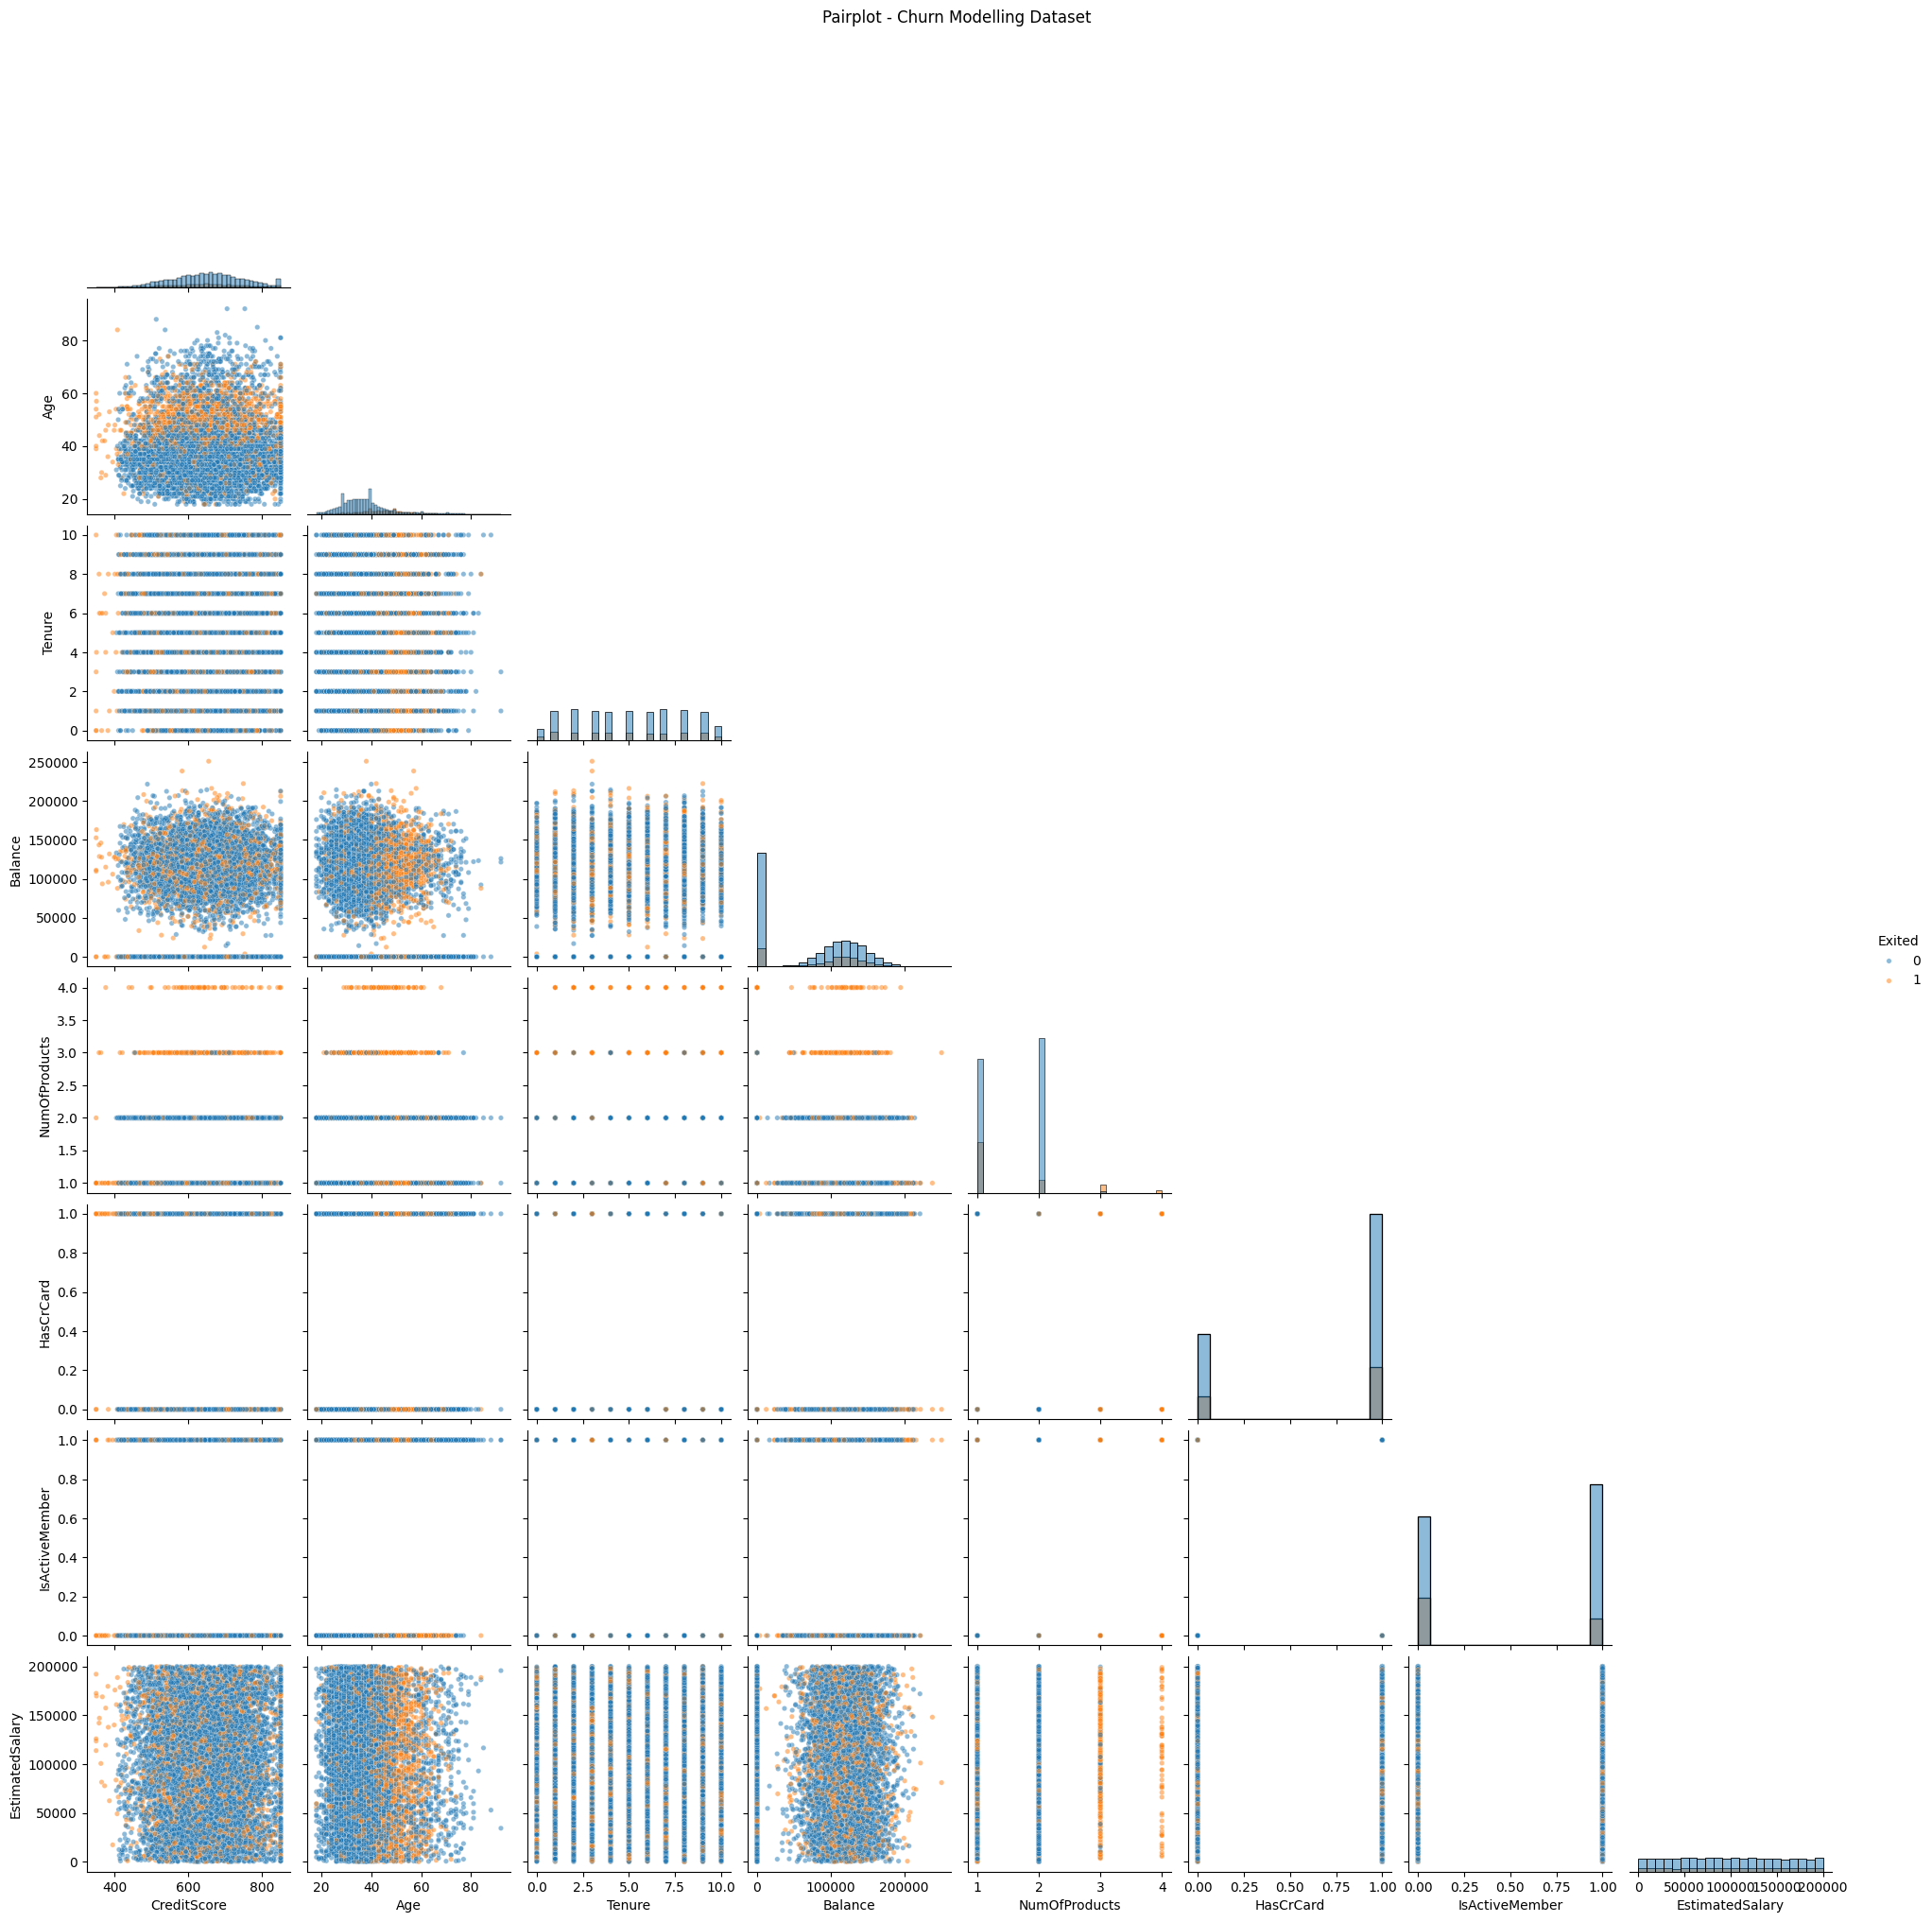

In [7]:
sns.pairplot(
    df[list(numerical_features)],
    hue="Exited",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 15}
)

plt.suptitle("Pairplot - Churn Modelling Dataset", y=1.02)
plt.show()

,Feature,Skewness
0,Exited,1.471611
1,Age,1.011320
2,NumOfProducts,0.745568
3,Tenure,0.010991
4,EstimatedSalary,0.002085
5,IsActiveMember,-0.060437
6,CreditScore,-0.071607
7,Balance,-0.141109
8,HasCrCard,-0.901812


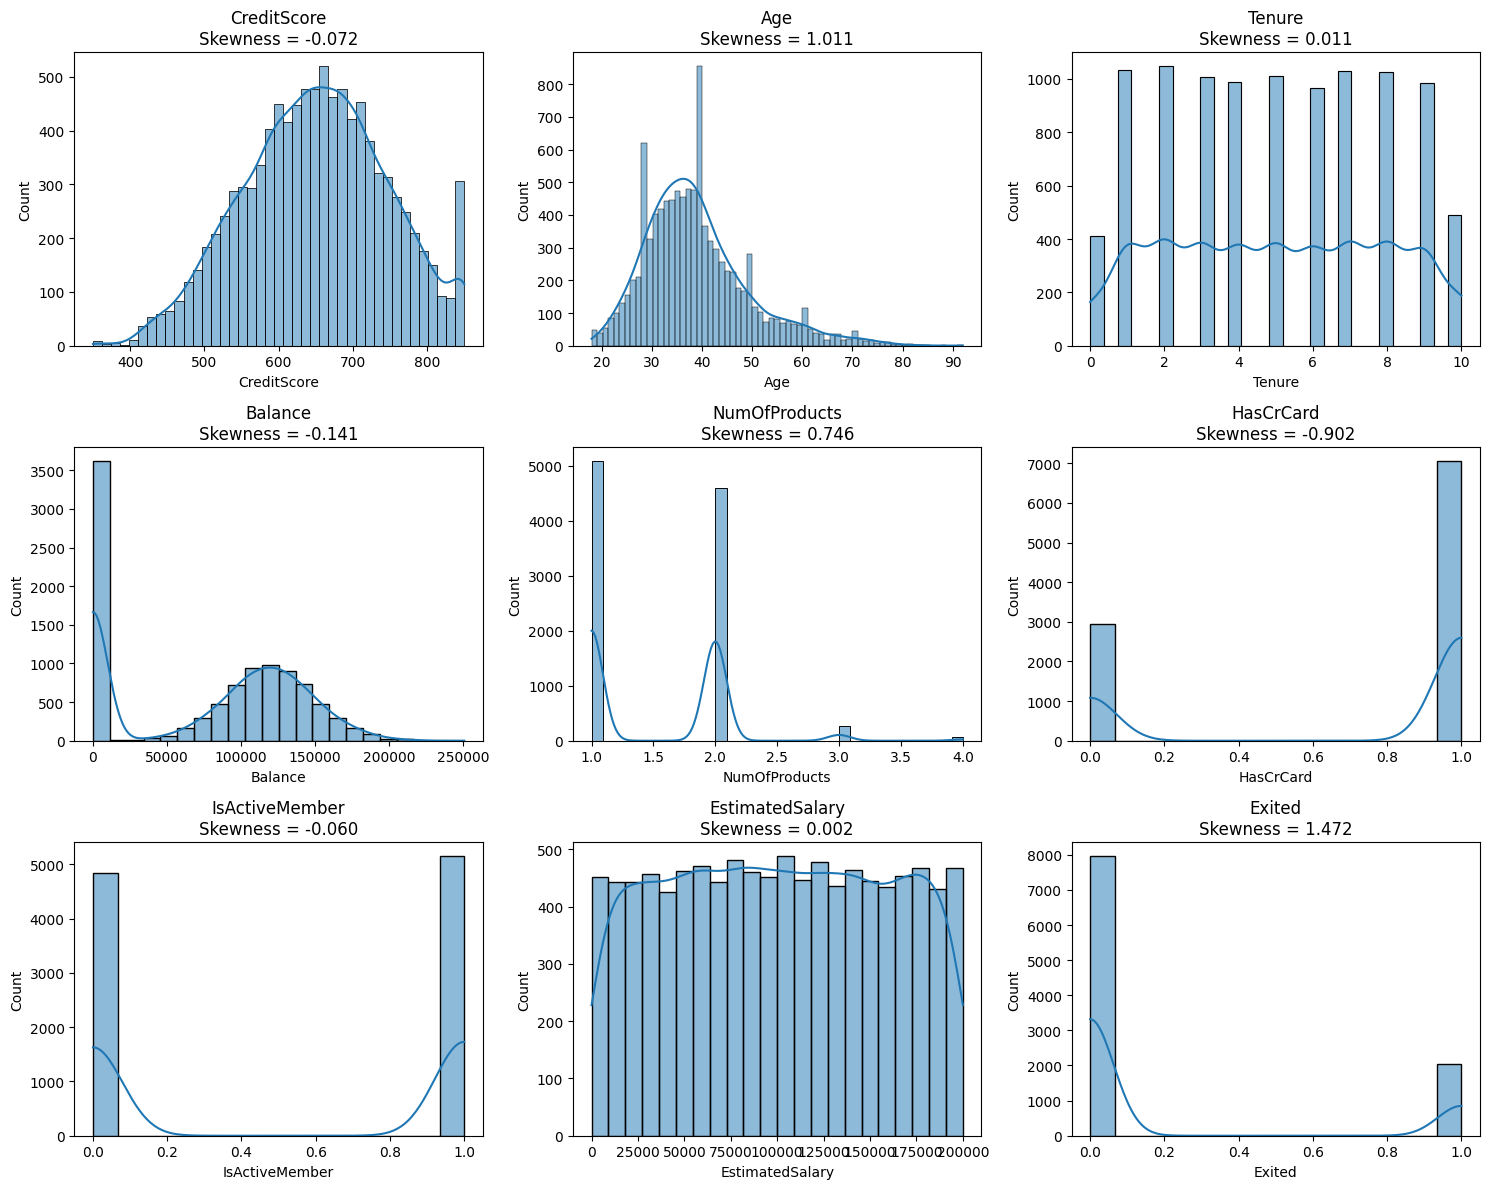

In [8]:
skewness = numerical_features.skew().sort_values(ascending=False)

skewness_df = pd.DataFrame({
    "Feature": skewness.index,
    "Skewness": skewness.values
})

display(skewness_df)

def categorize_skewness(value):
    if value > 1:
        return "Highly Right-Skewed"
    elif value > 0.5:
        return "Moderately Right-Skewed"
    elif value < -1:
        return "Highly Left-Skewed"
    elif value < -0.5:
        return "Moderately Left-Skewed"
    else:
        return "Approximately Symmetric"

skewness_df["Distribution"] = skewness_df["Skewness"].apply(
    categorize_skewness
)

numerical_columns = numerical_features.columns

n_cols = 3
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 4 * n_rows)
)

axes = np.array(axes).flatten()

for i, col in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        ax=axes[i]
    )

    skew_value = df[col].skew()

    axes[i].set_title(
        f"{col}\nSkewness = {skew_value:.3f}"
    )

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

# 2. Data Splitting

In [9]:
df = pd.read_csv('/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv')

drop_columns = ["RowNumber", "CustomerId", "Surname"]
drop_columns = [col for col in drop_columns if col in df.columns]

X = df.drop(columns=drop_columns + [TARGET])
y = df[TARGET].astype(int)

print("Fitur yang digunakan:")
print(X.columns.tolist())
print("\nUkuran X:", X.shape)
print("Ukuran y:", y.shape)

Fitur yang digunakan:
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Ukuran X: (10000, 10)
Ukuran y: (10000,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nProporsi kelas pada data latih:")
display(y_train.value_counts(normalize=True).sort_index())

print("\nProporsi kelas pada data uji:")
display(y_test.value_counts(normalize=True).sort_index())

X_train: (8000, 10)
X_test : (2000, 10)

Proporsi kelas pada data latih:


Exited
0    0.79625
1    0.20375
Name: proportion, dtype: float64


Proporsi kelas pada data uji:


Exited
0    0.7965
1    0.2035
Name: proportion, dtype: float64

# 3. Data Preprocessing

In [11]:
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

age_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("log_transform", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])


numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("age", age_pipeline, ["Age"]),
        ("num", numeric_pipeline, [
            col for col in numeric_features if col != "Age"
        ]),
        ("cat", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("Fitur numerik:", numeric_features)
print("Fitur kategorikal:", categorical_features)
display(preprocessor)

Fitur numerik: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']
Fitur kategorikal: ['Geography', 'Gender']


ColumnTransformer(transformers=[('age',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('log_transform',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=<ufunc 'log1p'>)),
                                                 ('scaler', StandardScaler())]),
                                 ['Age']),
                                ('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['CreditScore', 'Tenure', 'Balance',
                                  'NumOfProducts', 'HasCrCard',
                                  'IsActiveMember', 'EstimatedSalary']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['Geography', 'Gender'])])

# 4. Pelatihan dan Evaluasi Model Klasifikasi

## 4.1. Logistic Regression

In [12]:
model_lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
pipeline_model_lr = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", model_lr)
])

display(pipeline_model_lr)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['CreditScore', 'Tenure',
                                                   'Balance', 'NumOfProducts',
                                                   'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [13]:
print("Melatih model Logistic Regression . . .")
pipeline_model_lr.fit(X_train, y_train)
print("Model selesai dilatih")

Melatih model Logistic Regression . . .
Model selesai dilatih


In [14]:
y_pred_lr = pipeline_model_lr.predict(X_test)
print("Hasil prediksi: ", y_pred_lr)

Hasil prediksi:  [0 1 0 ... 1 0 0]


In [15]:
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr)
recall_lr = recall_score(y_test, y_pred_lr)
f1_lr = f1_score(y_test, y_pred_lr)

print("Akurasi : ", accuracy_lr)
print("Presisi : ", precision_lr)
print("Recall  : ", recall_lr)
print("F1-Score: ", f1_lr)

confusion_matrix_lr = confusion_matrix(y_test, y_pred_lr, labels=[0, 1])
print("\nConfusion Matrix\n", confusion_matrix_lr)

Akurasi :  0.708
Presisi :  0.3840104849279161
Recall  :  0.7199017199017199
F1-Score:  0.5008547008547009

Confusion Matrix
 [[1123  470]
 [ 114  293]]


Keterangan:
0: Tidak Churn
1: Churn


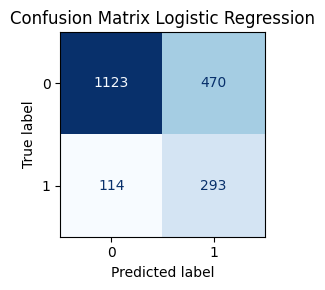

In [16]:
fig, ax = plt.subplots(figsize=(3, 3))

disp = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_lr,
    display_labels=["0", "1"]
)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion Matrix Logistic Regression")

print("Keterangan:")
print("0: Tidak Churn")
print("1: Churn")

plt.tight_layout()
plt.show()

In [17]:
print("Classification Report")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["Tidak churn (0)", "Churn (1)"],
    zero_division=0
))

Classification Report
                 precision    recall  f1-score   support

Tidak churn (0)       0.91      0.70      0.79      1593
      Churn (1)       0.38      0.72      0.50       407

       accuracy                           0.71      2000
      macro avg       0.65      0.71      0.65      2000
   weighted avg       0.80      0.71      0.73      2000



## 4.2. Random Forest

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('age',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('log_transform',
                                                                   FunctionTransformer(feature_names_out='one-to-one',
                                                                                       func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age']),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardSca...
                                                  ['CreditScore', 'Tenure',
                                                   'Balance', 'NumOfProducts',
                                                   'HasCrCard',
                                                   'IsActiveMember',
                                                   'EstimatedSalary']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Geography', 'Gender'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Melatih model Random Forest . . .
Model selesai dilatih
Hasil prediksi:  [0 0 0 ... 1 0 0]
Akurasi :  0.8565
Presisi :  0.7631578947368421
Recall  :  0.4275184275184275
F1-Score:  0.5480314960629922

Confusion Matrix
 [[1539   54]
 [ 233  174]]
Keterangan:
0: Tidak Churn
1: Churn


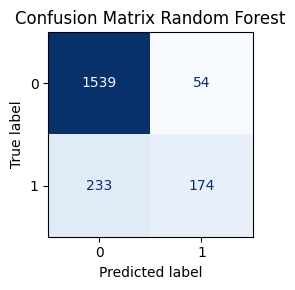

Classification Report
                 precision    recall  f1-score   support

Tidak churn (0)       0.87      0.97      0.91      1593
      Churn (1)       0.76      0.43      0.55       407

       accuracy                           0.86      2000
      macro avg       0.82      0.70      0.73      2000
   weighted avg       0.85      0.86      0.84      2000



In [18]:
model_rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
pipeline_model_rf = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", model_rf)
])

display(pipeline_model_rf)

print("Melatih model Random Forest . . .")
pipeline_model_rf.fit(X_train, y_train)
print("Model selesai dilatih")

y_pred_rf = pipeline_model_rf.predict(X_test)
print("Hasil prediksi: ", y_pred_rf)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf)
recall_rf = recall_score(y_test, y_pred_rf)
f1_rf = f1_score(y_test, y_pred_rf)

print("Akurasi : ", accuracy_rf)
print("Presisi : ", precision_rf)
print("Recall  : ", recall_rf)
print("F1-Score: ", f1_rf)

confusion_matrix_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
print("\nConfusion Matrix\n", confusion_matrix_rf)

fig, ax = plt.subplots(figsize=(3, 3))

disp = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_rf,
    display_labels=["0", "1"]
)
disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("Confusion Matrix Random Forest")

print("Keterangan:")
print("0: Tidak Churn")
print("1: Churn")

plt.tight_layout()
plt.show()

print("Classification Report")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Tidak churn (0)", "Churn (1)"],
    zero_division=0
))

# 5. Hyperparameter Tuning

In [19]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Konfigurasi cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Daftar model dan hyperparameter
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__solver": ["lbfgs"],
        "classifier__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 300],
        "classifier__max_depth": [None, 10],
        "classifier__class_weight": [None, "balanced"]
    }
}

In [20]:
from sklearn.base import clone

estimators = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    
    "Random Forest": RandomForestClassifier(
        random_state=42,
        n_jobs=1
    )
}

In [21]:
grid_results = []
best_models = {}

for model_name, estimator in estimators.items():

    print(f"\n{'='*60}")
    print(f"Training: {model_name}")
    print(f"{'='*60}")

    # Membuat pipeline
    pipeline = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", estimator)
    ])

    # Grid Search
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        verbose=1,
        refit=True,
        return_train_score=True
    )

    # Training menggunakan data latih
    grid_search.fit(X_train, y_train)

    # Menyimpan model terbaik
    best_models[model_name] = grid_search.best_estimator_

    # Menyimpan hasil
    grid_results.append({
        "Model": model_name,
        "Best CV F1": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

    print("Best CV F1:", round(grid_search.best_score_, 4))
    print("Best Parameters:", grid_search.best_params_)


Training: Logistic Regression
Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best CV F1: 0.4901
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}

Training: Random Forest
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best CV F1: 0.6104
Best Parameters: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__n_estimators': 100}


In [22]:
grid_results_df = pd.DataFrame(grid_results)

grid_results_df = grid_results_df.sort_values(
    by="Best CV F1",
    ascending=False
).reset_index(drop=True)

display(
    grid_results_df.style.format({
        "Best CV F1": "{:.4f}"
    })
)

,Model,Best CV F1,Best Parameters
0,Random Forest,0.6104,"{'classifier__class_weight': 'balanced', 'classifier__max_depth': 10, 'classifier__n_estimators': 100}"
1,Logistic Regression,0.4901,"{'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}"


In [23]:
for _, row in grid_results_df.iterrows():
    print(f"\nModel: {row['Model']}")
    print(f"Best CV F1: {row['Best CV F1']:.4f}")
    print("Best Parameters:")
    for param, value in row["Best Parameters"].items():
        print(f"  {param}: {value}")


Model: Random Forest
Best CV F1: 0.6104
Best Parameters:
  classifier__class_weight: balanced
  classifier__max_depth: 10
  classifier__n_estimators: 100

Model: Logistic Regression
Best CV F1: 0.4901
Best Parameters:
  classifier__C: 0.1
  classifier__class_weight: balanced
  classifier__solver: lbfgs


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

tuned_results = []
tuned_predictions = {}
tuned_confusion_matrices = {}

for model_name, best_model in best_models.items():

    # Prediksi data test
    y_pred = best_model.predict(X_test)

    tuned_predictions[model_name] = y_pred

    # Menghitung confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tuned_confusion_matrices[model_name] = cm

    # Menghitung metrik
    tuned_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    })

tuned_results_df = pd.DataFrame(tuned_results)

tuned_results_df = tuned_results_df.sort_values(
    by="F1-score",
    ascending=False
).reset_index(drop=True)

display(
    tuned_results_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-score": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.8385,0.5981,0.6290,0.6132
1,Logistic Regression,0.7075,0.3835,0.7199,0.5004


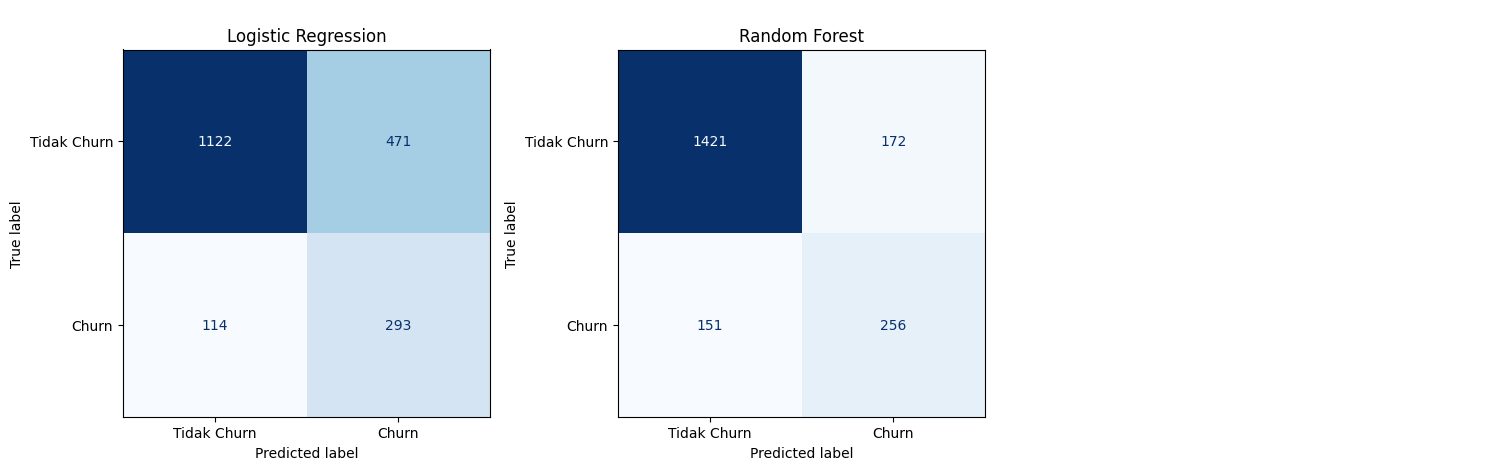

In [25]:
n_models = len(tuned_confusion_matrices)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(15, 5 * n_rows)
)

axes = np.array(axes).flatten()

for ax, (model_name, cm) in zip(
    axes, tuned_confusion_matrices.items()
):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Tidak Churn", "Churn"]
    )

    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False
    )

    ax.set_title(model_name)

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Latihan

1. Load ulang dataset Churn Modelling dengan nama variabel df_latihan!
   -

In [32]:
DATA_PATH = "/kaggle/input/datasets/shrutimechlearn/churn-modelling/Churn_Modelling.csv"

df_latihan = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df_latihan.head())

print("\n")
print("="*100)
print("Cek kondisi dataset:")
display(df_latihan.info())

print("\n")
print("="*100)
missing = df_latihan.isna().sum().sort_values(ascending=False)
print("Jumlah missing value per kolom:")
display(missing[missing > 0] if (missing > 0).any() else missing.to_frame("missing_value"))

Ukuran dataset: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0




Cek kondisi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


None



Jumlah missing value per kolom:


,missing_value
RowNumber,0
CustomerId,0
Surname,0
CreditScore,0
Geography,0
Gender,0
Age,0
Tenure,0
Balance,0
NumOfProducts,0


2. Lakukan feature selection dan data splitting dengan proporsi 70:30.
   -

In [27]:
fitur_numerik = df_latihan.drop(columns=['RowNumber', 'CustomerId']).select_dtypes(include=['int64', 'float64'])
matriks_corr = fitur_numerik.corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlation Matrix - Churn Modelling")
plt.tight_layout()
plt.show()

kolom_dihapus = ["RowNumber", "CustomerId", "Surname"]
kolom_dihapus = [kolom for kolom in kolom_dihapus if kolom in df_latihan.columns]
kolom_target = "Exited"

X_latihan = df_latihan.drop(columns=kolom_dihapus + [kolom_target])
y_latihan = df_latihan[kolom_target].astype(int)

print("Fitur yang digunakan:")
print(X_latihan.columns.tolist())
print("\nUkuran X:", X_latihan.shape)
print("Ukuran y:", y_latihan.shape)


3. Buatlah pipeline preprocessing! Berikan justifikasi pemilihan metode preprocessing!
   -

In [28]:
# Jawab : . . .




4. Buatlah kode GridSearchCV dengan 3-fold Cross Validation untuk model machine learning selain Logistic Regression dan Random Forest! Pilihlah minimal 3 model dan minimal 3 jenis parameter! Berikan justifikasi untuk: pemilihan model, pemilihan jenis parameter, dan penentuan ruang pemilihan parameter!
   -

In [29]:
# Jawab : . . .




5. Jalankan hyperparameter tuning yang sudah disiapkan oleh jawaban soal nomor 4.
   -

In [30]:
# Jawab : . . .




6. Prediksi data uji dengan menggunakan parameter terbaik tiap model!
   -

In [31]:
# Jawab : . . .




7. Analisislah model mana yang paling baik dan tentukan metrik evaluasi utama yang digunakan! Berikan justifikasinya!
   -

Jawab:
<br>
. . . . .